# Probabilistic SMS Spam Detection
**Yuvraj Chandak · 25BCE2561**  
Probability and Statistics — BAMAT207  
Dr. Veeramani S · Vellore Institute of Technology, Vellore

This notebook follows the eight assignment activities. It uses the official UCI corpus, removes exact duplicate messages before splitting, and evaluates a word-count Multinomial Naive Bayes model on unseen messages. Run all cells in order from the `project` folder. The source data is included, so analysis works offline after installing dependencies. In Colab, upload the project ZIP, extract it, and change into its `project` directory before running.

Dataset: https://doi.org/10.24432/C5CC84 (CC BY 4.0).

In [1]:
from pathlib import Path
import sys, json
if not Path('spam_detector.py').exists() and Path('project/spam_detector.py').exists():
    import os
    os.chdir('project')
import numpy as np
import pandas as pd
from IPython.display import display, Image
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from spam_detector import ROOT, load_data, word_probabilities, train, predict


## 1 Dataset handling
Read each record at its first tab, preserve message quotation marks, check missing and blank fields, reject invalid or conflicting labels, strip surrounding whitespace and remove exact duplicate text. Spam maps to 1; ham maps to 0. Source line IDs make each observation traceable. Case and internal whitespace variants are not merged.

In [2]:
df, audit = load_data()
display(pd.Series(audit, name='Cleaning audit'))
display(df[['source_line','label','target','message']].head())
assert not df.message.duplicated().any()


raw_rows                                                             5574
missing_rows                                                            0
blank_rows                                                              0
duplicate_rows                                                        414
conflicting_messages                                                    0
cleaned_rows                                                         5160
raw_counts                                     {'ham': 4827, 'spam': 747}
sha256                  7d039a24a6083ed9ef0f806ebad56bbb976e3aeb8de056...
Name: Cleaning audit, dtype: object

,source_line,label,target,message
0,1,ham,0,"Go until jurong point, crazy.. Available only ..."
1,2,ham,0,Ok lar... Joking wif u oni...
2,3,spam,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,4,ham,0,U dun say so early hor... U c already then say...
4,5,ham,0,"Nah I don't think he goes to usf, he lives aro..."


## 2 Class probabilities
The sample space consists of cleaned messages. P(Spam) is the fraction labelled spam; P(Ham) is its complement. This is an empirical distribution for this corpus, not a universal spam rate.

,count,probability
label,,
ham,4518,0.875581
spam,642,0.124419


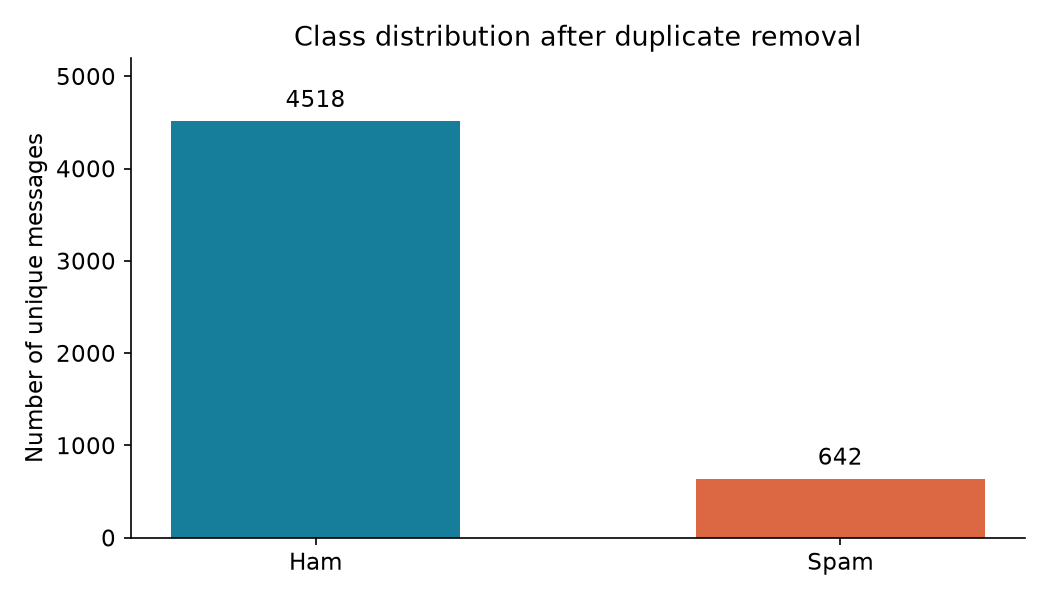

In [3]:
counts = df.label.value_counts()
p = df.target.mean()
display(pd.DataFrame({'count':counts, 'probability':counts / len(df)}))
metrics = train()  # Writes all reproducible results, figures and the trained pipeline.
display(Image(filename=str(ROOT/'results/class_distribution.png')))


## 3 Conditional probabilities and Bayes theorem
A word event is a case-insensitive whole-word match, counted once per message. For W = contains `free`:

P(Spam | W) = n(Spam ∩ W) / n(W).

Bayes gives the same value: P(W | Spam) × P(Spam) / P(W). Words such as `freedom` do not match `free`. These full-corpus descriptive proportions are not used to train or tune the classifier.

,word,containing,spam_containing,ham_containing,p_word,p_word_given_spam,p_spam_given_word,bayes_verification
0,free,199,144,55,0.038566,0.224299,0.723618,0.723618
1,prize,70,70,0,0.013566,0.109034,1.000000,1.000000
2,win,53,47,6,0.010271,0.073209,0.886792,0.886792
3,urgent,61,56,5,0.011822,0.087227,0.918033,0.918033
4,offer,30,24,6,0.005814,0.037383,0.800000,0.800000


Direct: 144.0/199.0 = 0.723618
Bayes: 0.224299 × 0.124419 / 0.038566 = 0.723618


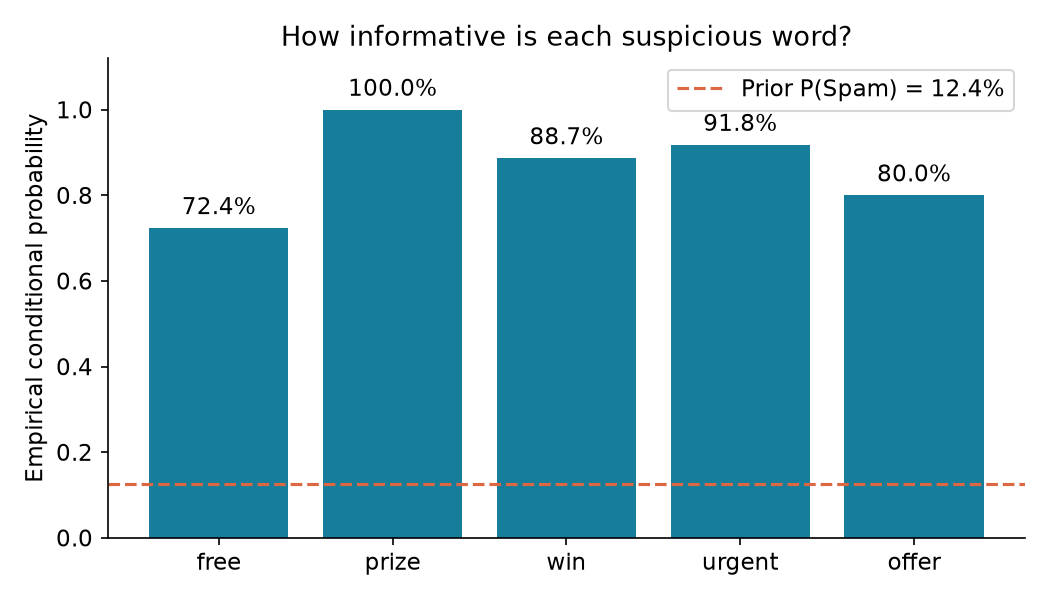

In [4]:
words = word_probabilities(df)
display(words.round(6))
np.testing.assert_allclose(words.p_spam_given_word, words.bayes_verification)
free = words.set_index('word').loc['free']
print(f"Direct: {free.spam_containing}/{free.containing} = {free.p_spam_given_word:.6f}")
print(f"Bayes: {free.p_word_given_spam:.6f} × {p:.6f} / {free.p_word:.6f} = {free.bayes_verification:.6f}")
display(Image(filename=str(ROOT/'results/word_probabilities.png')))


## 4 Bernoulli random variable
Y = 1 for spam and 0 for ham. Its probability mass function is P(Y=y)=p^y(1-p)^(1-y), y∈{0,1}.

E(Y)=0(1-p)+1p=p. Since Y²=Y, E(Y²)=p and Var(Y)=p-p²=p(1-p). This is the empirical distribution variance (ddof=0), not the unbiased sample variance.

In [5]:
print(f'E(Y) = {p:.8f}')
print(f'Var(Y) = {p*(1-p):.8f}')
assert np.isclose(df.target.var(ddof=0), p*(1-p))


E(Y) = 0.12441860
Var(Y) = 0.10893862


## 5 Stratified preparation
Use 80% for training and 20% for testing, with random_state=42 and stratify=y. The test size is rounded up to an integer. Fit the vocabulary only on training messages. This prevents the test vocabulary from entering training.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    df.message, df.target, test_size=0.2, random_state=42, stratify=df.target)
assert set(X_train).isdisjoint(set(X_test))
display(pd.DataFrame({'train':y_train.value_counts(), 'test':y_test.value_counts()}).rename(index={0:'Ham',1:'Spam'}))


,train,test
target,,
Ham,3614,904
Spam,514,128


## 6 Multinomial Naive Bayes
CountVectorizer lowercases text and uses its default tokens of at least two word characters. MultinomialNB uses alpha=1 (Laplace smoothing). No stopword removal, stemming, tuning or test-set-based feature selection is applied. The fitted pipeline keeps preprocessing and prediction consistent.

For class c and vocabulary term j, θ(c,j) = [N(c,j)+1]/[Σk N(c,k)+V]. The class score is log P(c)+Σj xj log θ(c,j). Normalizing the two scores gives the displayed model probabilities.

In [7]:
model = Pipeline([('vectorizer', CountVectorizer()), ('classifier', MultinomialNB())])
model.fit(X_train, y_train)
print('Training vocabulary size:', len(model.named_steps['vectorizer'].vocabulary_))


Training vocabulary size: 7673


## 7 Held-out evaluation
Spam is the positive class. Rows of the confusion matrix are actual labels; columns are predictions, ordered [Ham, Spam]. False negatives are missed spam; false positives are genuine messages incorrectly blocked. Compare accuracy against always predicting ham because the classes are imbalanced.

Accuracy: 0.9825581395348837
Always-ham baseline: 0.875968992248062
              precision    recall  f1-score   support

         Ham   0.986813  0.993363  0.990077       904
        Spam   0.950820  0.906250  0.928000       128

    accuracy                       0.982558      1032
   macro avg   0.968816  0.949806  0.959039      1032
weighted avg   0.982349  0.982558  0.982378      1032



,Predicted ham,Predicted spam
Actual ham,898,6
Actual spam,12,116


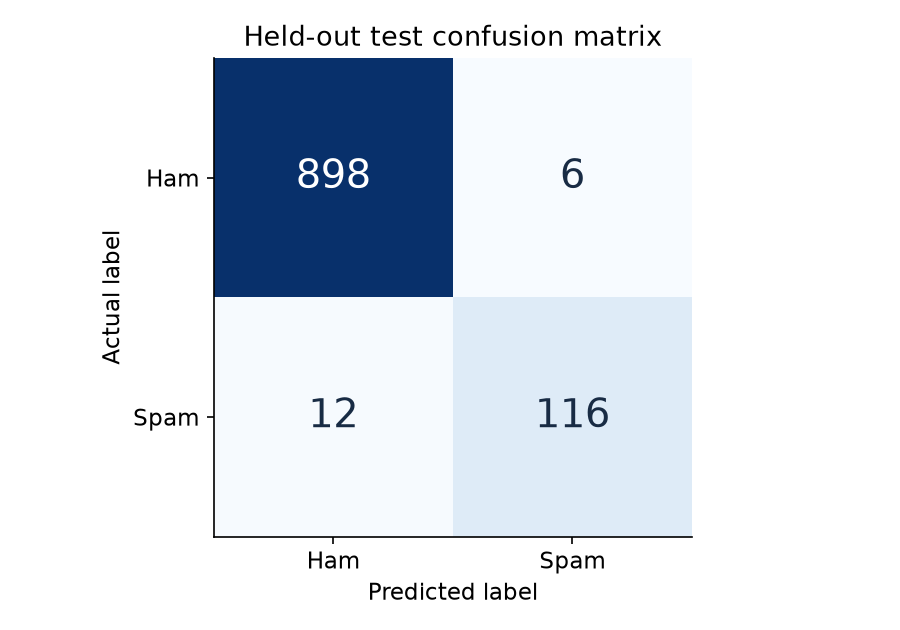

,source_line,label,message,error_type,p_spam
0,4730,ham,I (Career Tel) have added u as a contact on IN...,False positive,9.678168e-01
1,1501,spam,"SMS. ac JSco: Energy is high, but u may not kn...",False negative,3.791523e-01
2,3361,spam,Sorry I missed your call let's talk when you h...,False negative,2.180240e-06
3,4863,ham,Nokia phone is lovly..,False positive,9.378889e-01
4,3133,spam,LookAtMe!: Thanks for your purchase of a video...,False negative,2.067927e-03
5,685,spam,Hi I'm sue. I am 20 years old and work as a la...,False negative,8.297527e-02
6,2403,spam,Babe: U want me dont u baby! Im nasty and have...,False negative,5.045376e-08
7,4601,ham,Have you laid your airtel line to rest?,False positive,8.711153e-01


In [8]:
pred = model.predict(X_test)
print('Accuracy:', accuracy_score(y_test, pred))
print('Always-ham baseline:', (y_test == 0).mean())
print(classification_report(y_test, pred, target_names=['Ham','Spam'], digits=6))
cm = confusion_matrix(y_test, pred, labels=[0,1])
display(pd.DataFrame(cm, index=['Actual ham','Actual spam'], columns=['Predicted ham','Predicted spam']))
assert np.isclose(accuracy_score(y_test, pred), metrics['accuracy'])
display(Image(filename=str(ROOT/'results/confusion_matrix.png')))
errors = pd.read_csv(ROOT/'results/errors.csv')
display(errors[['source_line','label','message','error_type','p_spam']].head(8))


## 8 Real-time prediction
Edit `message` and rerun. The exact probabilities are calculated by the model; the assignment's 0.96 and 0.04 are illustrative. Empty input is rejected. If none of the tokens is known, the result falls back to training priors with a warning.

In [9]:
message = 'Congratulations! You have won a free prize. Claim now.'
result = predict(message, model)
print('Prediction:', result['prediction'])
print(f"P(Spam | Message) = {result['p_spam']:.8f}")
print(f"P(Ham | Message) = {result['p_ham']:.8f}")
print(result['warning'])
display(pd.DataFrame(result['contributions']))


Prediction: Spam
P(Spam | Message) = 0.99999980
P(Ham | Message) = 0.00000020



,word,count,log_odds
0,claim,1,5.344838
1,prize,1,5.170484
2,congratulations,1,3.329935
3,free,1,2.345926
4,won,1,2.049001
5,you,1,-0.955150
6,now,1,0.447226
7,have,1,-0.347516


## Interpretation and limitations
Naive Bayes assumes conditional token independence and ignores word order. Its probabilities need not be calibrated, so high confidence does not establish correctness. Historical English SMS data does not establish performance on modern scams, other languages or obfuscated messages. Exact deduplication does not eliminate near-duplicate templates. The reported metrics describe one reproducible split, not a deployment guarantee.

For classroom use, run `python demo.py` or `python spam_detector.py interactive`. Read `DEMO_GUIDE.md` for the presentation sequence and viva questions.

## References
1. Almeida and Hidalgo (2011), SMS Spam Collection, UCI: https://doi.org/10.24432/C5CC84
2. scikit-learn, Naive Bayes: https://scikit-learn.org/stable/modules/naive_bayes.html
3. CountVectorizer: https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html
4. train_test_split: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
